# Lab 3 — Bài thực hành 4: So sánh sự tương đồng của các hình ảnh sử dụng Wavelet (Python)

**Nguồn:** Chương 3 — Phát hiện đặc trưng và đối sánh ảnh (Part 1, slide 16–18).

**Ý tưởng:** dùng **wavelet hash** — biến đổi wavelet rút trích thông tin tần số của ảnh,
lượng tử hóa hệ số thành chuỗi bit; hai ảnh giống nhau cho hash gần nhau
(khoảng cách Hamming nhỏ). Kỹ thuật này dùng cho tìm ảnh tương tự / phát hiện vi phạm bản quyền.

**Pipeline:**
```
Ảnh → grayscale + resize 128×128 → DWT (db4, level 3)
    → subband LL → ngưỡng median → hash 484 bit
    → Hamming distance giữa các cặp → ngưỡng quyết định
    → Accuracy / Recall / Specificity / Precision / ROC
```

**Nội dung thực hiện theo đề bài:**

| # | Yêu cầu |
|---|---------|
| 1 | Chuẩn bị dữ liệu: các cặp ảnh tương tự / không tương tự |
| 2 | Trích xuất wavelet (chuyển từng ảnh thành ma trận wavelet) |
| 3 | Tạo mã băm từ hệ số wavelet đã lượng tử hóa |
| 4 | So sánh hash bằng khoảng cách Hamming |
| 5 | Đánh giá: accuracy, recall (sensitivity), specificity, precision, ROC |
| 6* | Nâng cao: khảo sát các phương pháp băm wavelet, so sánh hiệu suất |
| 7* | Nâng cao: ứng dụng tìm kiếm hình ảnh theo wavelet hash |

## 0. Cài đặt và import

In [1]:
from pathlib import Path
import cv2, pywt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score

import wavelet_hash as wh    # hàm hash / hamming / evaluate
import prepare_data as prep  # tải ảnh + sinh bộ cặp

plt.rcParams["figure.dpi"] = 110

# Tham số mặc định của pipeline (dùng lại ở các phần sau)
CONFIG = dict(wavelet="db4", level=3, size=128)  # → LL 22×22 → hash 484 bit
print("pywt", pywt.__version__, "| cv2", cv2.__version__)

pywt 1.8.0 | cv2 5.0.0


## 1. Chuẩn bị dữ liệu (Task 1)

- **10 ảnh gốc** tải từ bộ mẫu OpenCV (baboon, board, building, butterfly, fruits,
  home, starry_night, sudoku, messi5, aero1) — 10 nội dung khác nhau.
- **Cặp dương (label = 1):** ảnh gốc và phiên bản biến đổi của chính nó —
  xoay 12°, thu nhỏ 0.8, nhiễu Gauss σ=15, tăng sáng +30%, nén JPEG q=30
  (mô phỏng "cùng đối tượng, góc nhìn/điều kiện khác nhau").
- **Cặp âm (label = 0):** ảnh biến đổi của nguồn này ghép với **ảnh gốc của nguồn khác**.

→ Tổng **50 dương + 50 âm**, sinh bằng seed cố định nên chạy lại cho cùng kết quả.

In [2]:
prep.download_raw()               # tải 10 ảnh gốc lần đầu (bỏ qua nếu đã có)
df_pairs = prep.build_dataset()   # sinh ảnh biến đổi + pairs.csv
print(df_pairs["label"].value_counts(), end="\n\n")
df_pairs.groupby(["transform", "label"]).size().unstack()

label
1    50
0    50
Name: count, dtype: int64



label,0,1
transform,,
bright30,10,10
jpeg30,10,10
noise15,10,10
rot12,10,10
scale08,10,10


### Xem trước các cặp ảnh

Đã lưu: outputs/fig_01_dataset_pairs.png


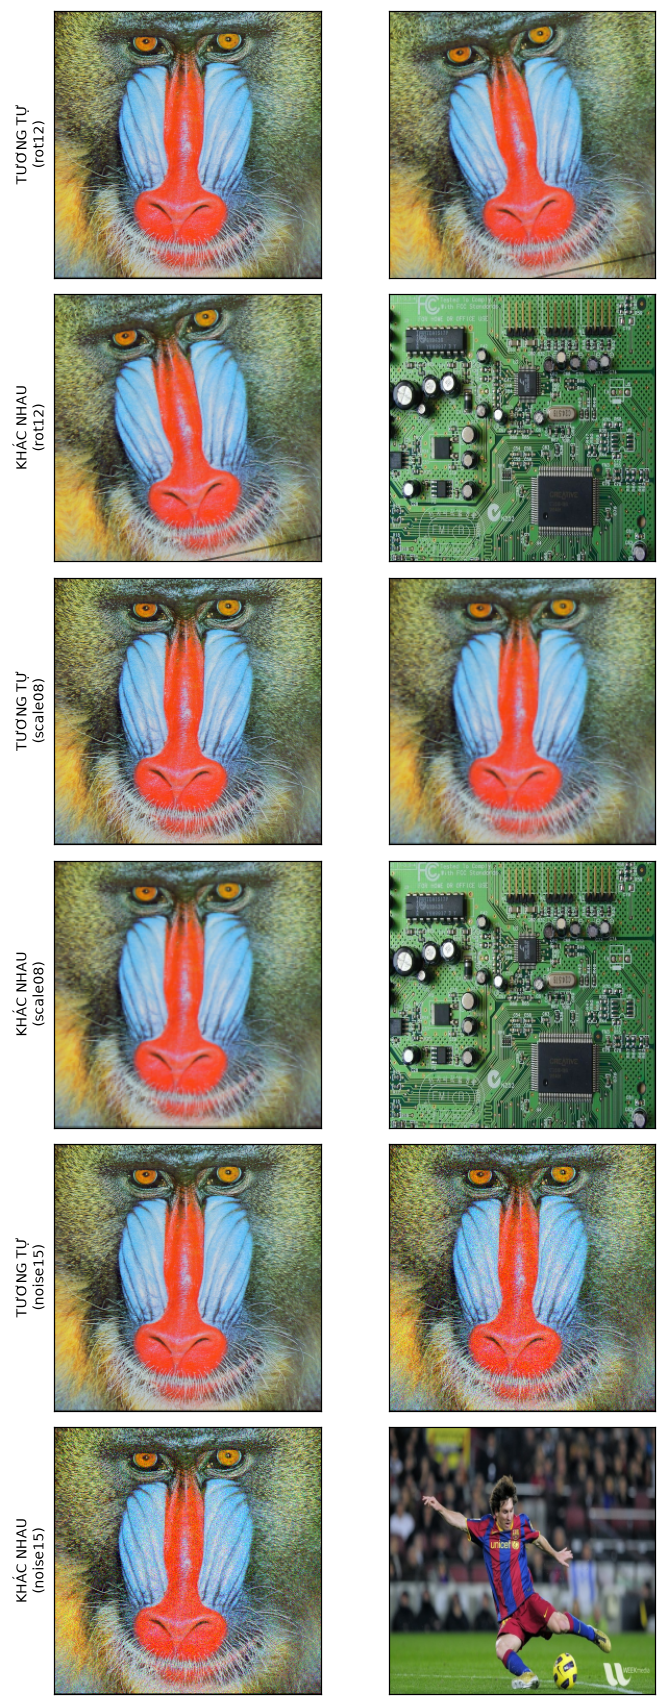

In [3]:
def load_img(name):
    """Đọc ảnh từ data/processed/images."""
    return wh.imread_unicode(wh.PROC_DIR / "images" / name)

def show_pairs(rows, fname=None):
    """Hiển thị mỗi cặp trên một dòng: ảnh A | ảnh B."""
    rows = rows.reset_index(drop=True)
    fig, axes = plt.subplots(len(rows), 2, figsize=(7, 2.6 * len(rows)))
    for ax, (_, r) in zip(axes, rows.iterrows()):
        ax[0].imshow(cv2.cvtColor(load_img(r.path_a), cv2.COLOR_BGR2RGB))
        ax[1].imshow(cv2.cvtColor(load_img(r.path_b), cv2.COLOR_BGR2RGB))
        tag = "TƯƠNG TỰ" if r.label == 1 else "KHÁC NHAU"
        for a in ax:
            a.set_xticks([]); a.set_yticks([])
        ax[0].set_ylabel(f"{tag}\n({r['transform']})", fontsize=9)
    plt.tight_layout()
    if fname:
        wh.save_fig(fig, fname)
    plt.show()

show_pairs(df_pairs.groupby("label").head(3), "fig_01_dataset_pairs.png")

## 2. Trích xuất đặc trưng wavelet (Task 2)

**Biến đổi wavelet rời rạc 2 chiều (DWT2)** tách ảnh thành 4 subband mỗi mức:
- **LL** (approximation): nội dung xấp xỉ của ảnh, ít bị ảnh hưởng bởi nhiễu / ánh sáng / nén;
- **HL / LH / HH** (detail): biên ngang / dọc / chéo — nhạy với biến đổi.

→ Ta hash trên **LL của mức sâu (level 3)** vì nó phản ánh "nội dung" của ảnh
và ổn định trước các biến đổi nhẹ. Do hiệu ứng biên của bộ lọc (dài 8),
ảnh 128×128 ở level 3 cho LL **22×22** (484 hệ số).

Đã lưu: outputs/fig_02_wavelet_subbands.png


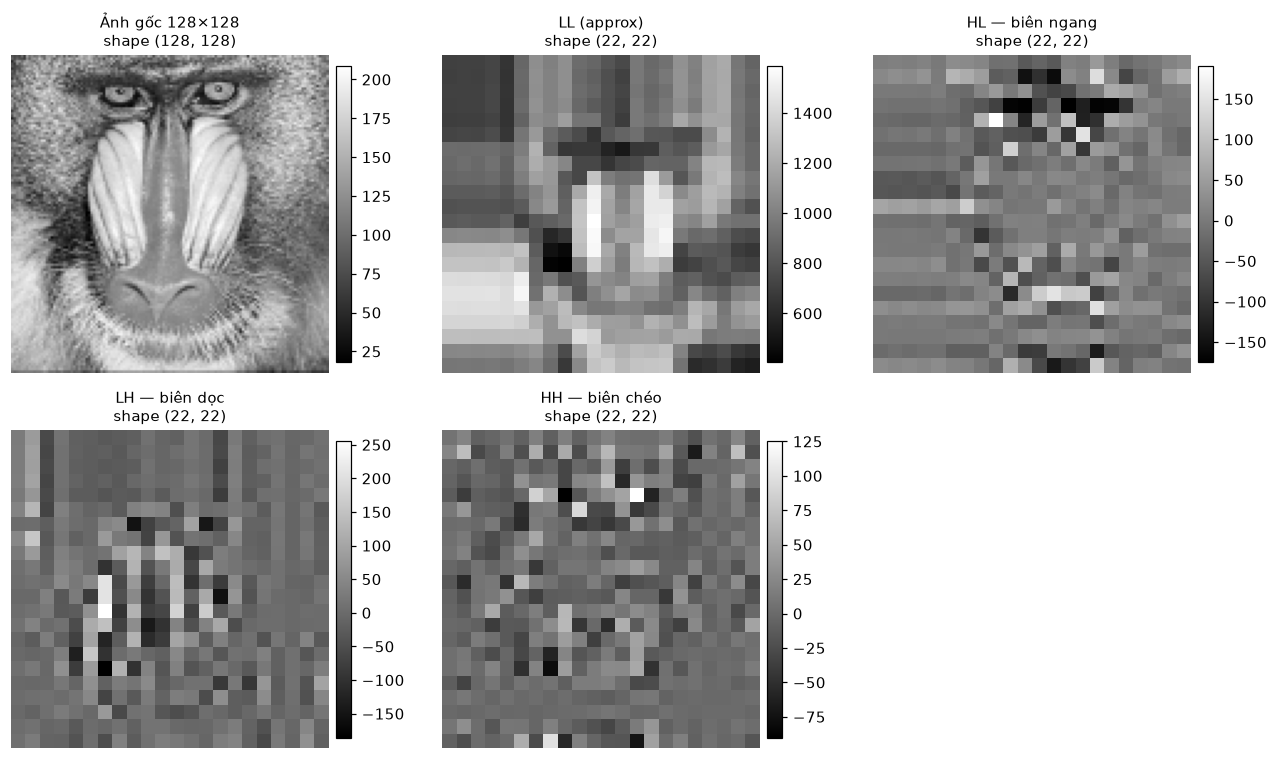

In [4]:
img = load_img(df_pairs.loc[0, "path_a"])   # baboon
g = wh.to_gray(img, CONFIG["size"])
coeffs = pywt.wavedec2(g, CONFIG["wavelet"], level=CONFIG["level"])
ll, details = coeffs[0], coeffs[1]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
views = [(g, "Ảnh gốc 128×128"), (ll, "LL (approx)"),
         (details[0], "HL — biên ngang"), (details[1], "LH — biên dọc"),
         (details[2], "HH — biên chéo")]
for ax, (v, t) in zip(axes.flat, views):
    im = ax.imshow(v, cmap="gray")
    ax.set_title(f"{t}\nshape {v.shape}", fontsize=10)
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
axes.flat[5].axis("off")
plt.tight_layout()
wh.save_fig(fig, "fig_02_wavelet_subbands.png")
plt.show()

In [5]:
# Kích thước LL theo từng mức phân rã (cùng ảnh baboon)
shapes = {}
for lv in (1, 2, 3):
    ll_lv = pywt.wavedec2(g, "db4", level=lv)[0]
    shapes[f"level {lv}"] = f"{ll_lv.shape[0]}×{ll_lv.shape[1]}"
pd.Series(shapes, name="Kích thước LL")

level 1    67×67
level 2    37×37
level 3    22×22
Name: Kích thước LL, dtype: str

## 3. Tạo mã băm từ hệ số wavelet (Task 3)

Quy trình 3 bước (theo slide): **biến đổi wavelet → lượng tử hóa hệ số → tạo băm**.
Nhiệm vụ 3 chỉ nói "lượng tử hóa + tạo băm"; ở đây có 2 cách:

1. **Median threshold (bản chính, dùng toàn bài):**
   `bit = 1` nếu hệ số LL > median(LL); ngược lại 0.
   Ổn định với biến đổi ánh sáng toàn cục (median bất biến khi cả ảnh cùng sáng/dark).
2. **Bản pseudocode trong slide:** lượng tử hóa bước 2 rồi `bit = giá trị % 2`
   (`pywt.quantize` không có trong PyWavelets hiện hành → tự viết bằng `np.round(coeff / step)`).

⚠️ Pseudocode slide có **3 hạn chế** mà bản này đã sửa:
- `coeffs` từ `pywt.wavedec2` là *tuple lồng nhau* (LL mảng + các tuple detail) →
  flatten trực tiếp sẽ lỗi; ở đây chỉ dùng LL;
- phải **resize về kích thước cố định** (128×128) trước, nếu không LL khác kích thước → hash không so được;
- "hash" phải cố định chiều để so Hamming giữa mọi ảnh — LL 22×22 cho 484 bit là đủ phân biệt.

Độ dài hash: 484 bit (LL 22×22)
Đã lưu: outputs/fig_03_hash_visualize.png


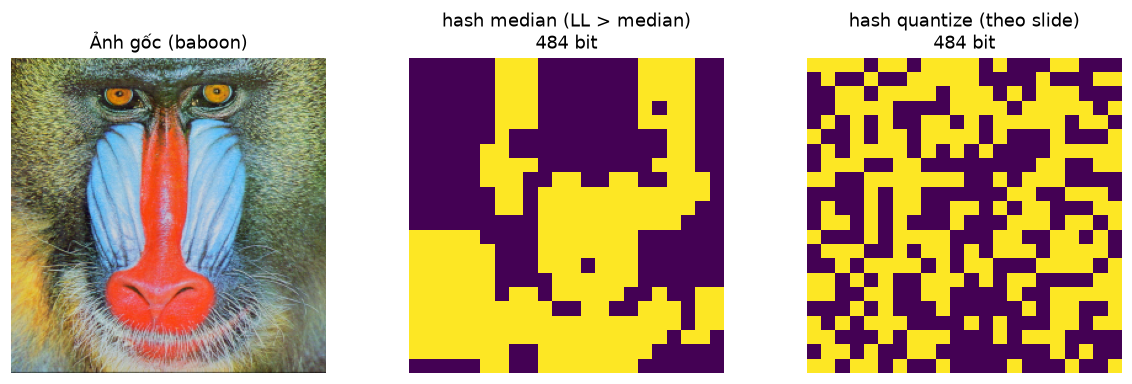

In [6]:
h_med = wh.wavelet_hash(img, **CONFIG)           # bản median (dùng chính)
h_q   = wh.wavelet_hash_quantize(img, **CONFIG)  # bản theo slide

print(f"Độ dài hash: {h_med.size} bit (LL {int(round(h_med.size**0.5))}×{int(round(h_med.size**0.5))})")

side = int(round(h_med.size**0.5))
fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].set_title("Ảnh gốc (baboon)")
axes[0].axis("off")
for ax, h, t in [(axes[1], h_med, "hash median (LL > median)"),
                 (axes[2], h_q, "hash quantize (theo slide)")]:
    ax.imshow(h.reshape(side, side), cmap="viridis", interpolation="nearest")
    ax.set_title(f"{t}\n{h.size} bit")
    ax.axis("off")
plt.tight_layout()
wh.save_fig(fig, "fig_03_hash_visualize.png")
plt.show()

## 4. So sánh hash — khoảng cách Hamming (Task 4)

Tính hash cho **60 ảnh** (10 gốc + 50 biến đổi), rồi khoảng cách Hamming cho từng cặp
trong `pairs.csv`, chuẩn hóa về [0,1]: (số bit khác nhau) / tổng số bit.

In [7]:
img_dir = wh.PROC_DIR / "images"
all_hashes = {f.name: wh.wavelet_hash(load_img(f.name), **CONFIG)
              for f in sorted(img_dir.iterdir())}
print("Số ảnh:", len(all_hashes))

df_pairs["distance"] = wh.pairwise_distances(all_hashes, df_pairs[["path_a", "path_b"]])
df_pairs["distance"].describe().round(3)

Số ảnh: 60


count    100.000
mean       0.277
std        0.248
min        0.000
25%        0.004
50%        0.287
75%        0.515
max        0.686
Name: distance, dtype: float64

Đã lưu: outputs/fig_04_distance_hist.png


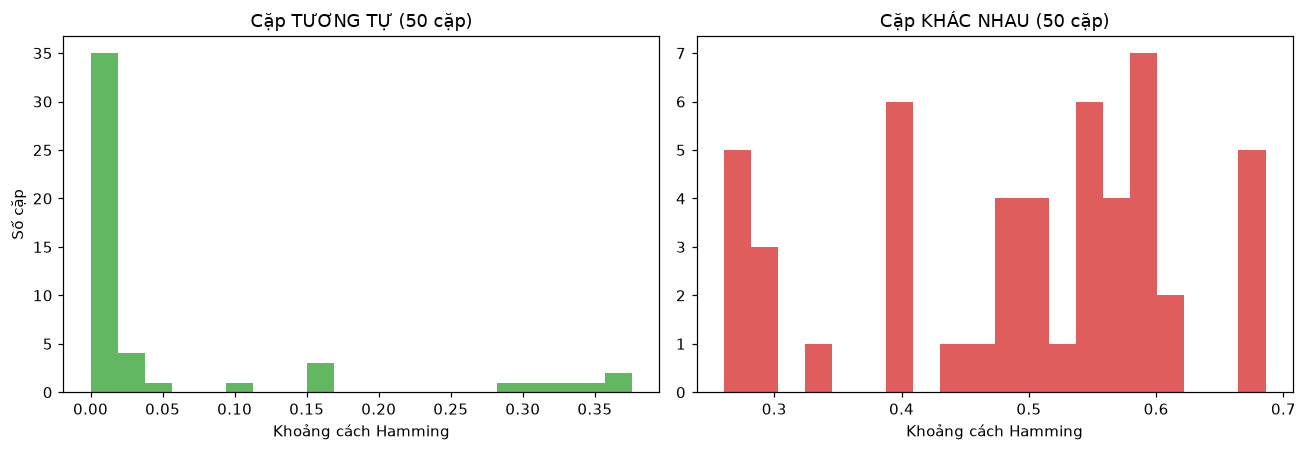

label=0: min=0.260  mean=0.494  max=0.686
label=1: min=0.000  mean=0.059  max=0.376


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, lab, color in [(axes[0], 1, "tab:green"), (axes[1], 0, "tab:red")]:
    sub = df_pairs[df_pairs.label == lab]
    ax.hist(sub["distance"], bins=20, color=color, alpha=.75)
    ax.set_title(f"Cặp {'TƯƠNG TỰ' if lab else 'KHÁC NHAU'} ({len(sub)} cặp)")
    ax.set_xlabel("Khoảng cách Hamming")
axes[0].set_ylabel("Số cặp")
plt.tight_layout()
wh.save_fig(fig, "fig_04_distance_hist.png")
plt.show()

for lab in (0, 1):
    d = df_pairs.loc[df_pairs.label == lab, "distance"]
    print(f"label={lab}: min={d.min():.3f}  mean={d.mean():.3f}  max={d.max():.3f}")

**Nhận xét:** hai nhóm tách khá rõ — phần lớn cặp tương tự có khoảng cách nhỏ
(dưới ~0.15), cặp khác nhau thường > 0.25. Tồn tại vùng **giao nhau** ở giữa
→ không có ngưỡng 100% chính xác; cần chọn ngưỡng hợp lý và đánh giá định lượng (phần 5).

## 5. Đánh giá hiệu suất (Task 5)

Chia ngẫu nhiên 70/30 (stratify theo label, seed cố định):
- **Train** chọn ngưỡng tối ưu theo Youden's J = max(TPR − FPR) trên ROC train;
- **Test** chấm accuracy, recall (sensitivity), specificity, precision, F1 + vẽ ROC.

Quy ước: dự đoán **tương tự** khi **distance ≤ ngưỡng**. Định nghĩa:

| Hiệu suất | Công thức | Ý nghĩa |
|---|---|---|
| Accuracy | (TP+TN)/N | tổng cặp được phân loại đúng |
| Recall (sensitivity) | TP/(TP+FN) | cặp tương tự được nhận đúng |
| **Specificity (độ đặc hiệu)** | TN/(TN+FP) | cặp **không** tương tự được loại đúng |
| Precision | TP/(TP+FP) | trong phần dự đoán tương tự, bao nhiêu đúng |

> ⚠️ Slide ghi *"Độ đặc hiệu: precision"* là **nhầm lẫn**: độ đặc hiệu = **specificity**
> (đo TN rate), còn precision là phép đo khác (giá trị dự báo dương).

In [9]:
tr_idx, te_idx = train_test_split(df_pairs.index, test_size=0.3,
                                  random_state=42, stratify=df_pairs.label)
d_tr, y_tr = df_pairs.loc[tr_idx, "distance"].values, df_pairs.loc[tr_idx, "label"].values
d_te, y_te = df_pairs.loc[te_idx, "distance"].values, df_pairs.loc[te_idx, "label"].values

thr = wh.pick_threshold(d_tr, y_tr)
res = wh.evaluate(d_te, y_te, thr)
print(f"Ngưỡng chọn trên train (Youden): {thr:.3f}\n")
pd.Series(res)

Ngưỡng chọn trên train (Youden): 0.157



threshold                0.157025
tp                      13.000000
tn                      15.000000
fp                       0.000000
fn                       2.000000
accuracy                 0.933333
recall (sensitivity)     0.866667
specificity              1.000000
precision                1.000000
f1                       0.928571
dtype: float64

Đã lưu: outputs/fig_05_confusion_roc.png


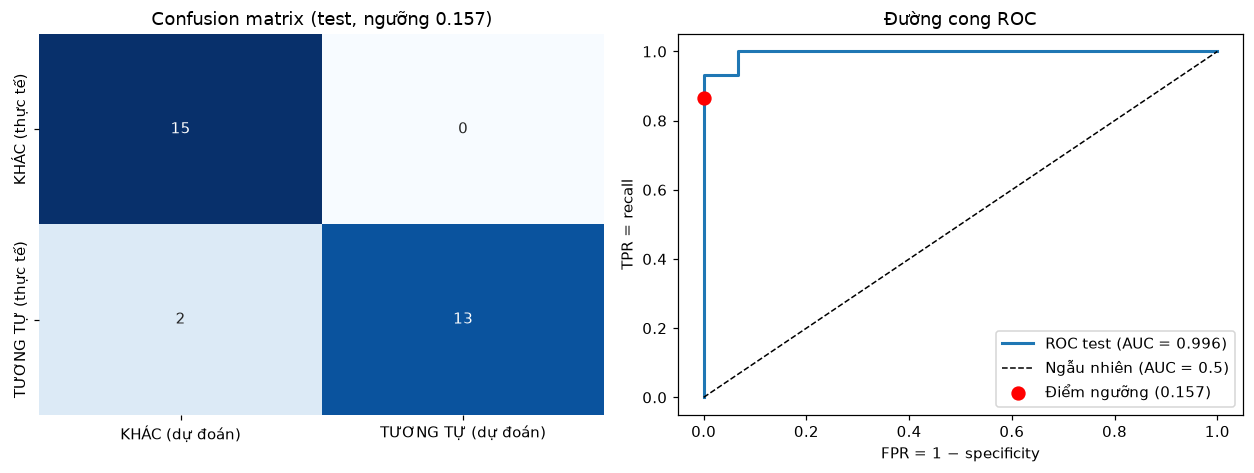

In [10]:
# Confusion matrix + ROC trên tập test
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4))
cm = np.array([[res["tn"], res["fp"]], [res["fn"], res["tp"]]])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=["KHÁC (dự đoán)", "TƯƠNG TỰ (dự đoán)"],
            yticklabels=["KHÁC (thực tế)", "TƯƠNG TỰ (thực tế)"], ax=axes[0])
axes[0].set_title(f"Confusion matrix (test, ngưỡng {thr:.3f})")

fpr, tpr, _ = roc_curve(y_te, -d_te)
auc_te = roc_auc_score(y_te, -d_te)
axes[1].plot(fpr, tpr, lw=2, label=f"ROC test (AUC = {auc_te:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Ngẫu nhiên (AUC = 0.5)")
axes[1].scatter(1 - res["specificity"], res["recall (sensitivity)"], c="red", s=70, zorder=5,
                label=f"Điểm ngưỡng ({thr:.3f})")
axes[1].set_xlabel("FPR = 1 − specificity"); axes[1].set_ylabel("TPR = recall")
axes[1].set_title("Đường cong ROC"); axes[1].legend(loc="lower right")
plt.tight_layout()
wh.save_fig(fig, "fig_05_confusion_roc.png")
plt.show()

### Sức bền theo từng kiểu biến đổi

In [11]:
tab = df_pairs.groupby(["transform", "label"])["distance"].agg(["mean", "max"]).unstack()
tab.round(3)

mean           max       
label          0      1      0      1
transform                            
bright30   0.494  0.018  0.674  0.050
jpeg30     0.489  0.007  0.686  0.017
noise15    0.482  0.007  0.686  0.017
rot12      0.467  0.261  0.591  0.376
scale08    0.539  0.004  0.686  0.012

**Nhận xét** (căn cứ theo kết quả chạy):
- scale08 / noise15 / bright30 / jpeg30: mean của nhóm dương nhỏ → hash ổn định với các biến đổi này.
- **rot12** (xoay) là biến đổi khó nhất: nội dung dịch chuyển vị trí, nhiều bit đổi dấu → mean dương lớn nhất;
  đây là nguyên nhân chính tạo ra các cặp FN.
- Nhóm âm luôn có mean ~0.45–0.55 với mọi kiểu biến đổi (chỉ phụ thuộc nội dung hai ảnh nguồn).

### Phân tích các cặp bị phân loại sai

In [12]:
df_pairs["pred"] = (df_pairs["distance"] <= thr).astype(int)
errs = df_pairs[df_pairs.pred != df_pairs.label]
fp = errs[errs.label == 0].nsmallest(3, "distance")   # khác nhau nhưng dự đoán tương tự
fn = errs[errs.label == 1].nlargest(3, "distance")   # tương tự nhưng dự đoán khác nhau
print(f"FP: {len(fp)}  |  FN: {len(fn)}  (trên {len(df_pairs)} cặp)")

FP: 0  |  FN: 3  (trên 100 cặp)


Không có cặp FP (false positive).


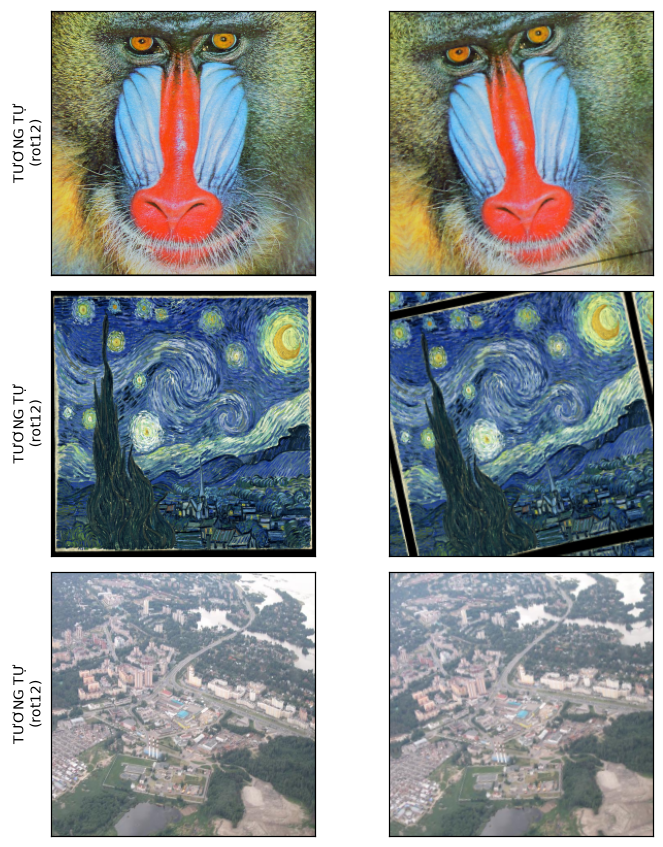

In [13]:
# hiển thị tối đa 3 FP / 3 FN (nếu không có thì bỏ qua)
if len(fp):
    show_pairs(fp)
else:
    print("Không có cặp FP (false positive).")
if len(fn):
    show_pairs(fn)
else:
    print("Không có cặp FN (false negative).")

**Nguyên nhân thường gặp:** các FP là cặp hai nguồn có phân bố tần số/bảng màu giống nhau;
các FN thường là biến đổi xoay/scale mạnh (khoảng cách vượt ngưỡng dù là cùng nguồn).

## 6* Nâng cao: khảo sát các phương pháp băm wavelet (Task 6)

So sánh 2×3×3 = **18 cấu hình**:
- **Cách tạo bit:** `median` (LL > median) vs `quantize` (theo slide, bit % 2);
- **Bộ lọc wavelet:** `haar`, `db4`, `sym4`;
- **Mức phân rã:** level 1/2/3 — mức càng sâu hash càng ngắn.

Mỗi cấu hình: tính lại toàn bộ hash + khoảng cách, chọn ngưỡng trên **cùng bộ train**,
đo accuracy trên **test** và AUC trên toàn bộ cặp.

In [14]:
rows = []
for method in ("median", "quantize"):
    fn_hash = wh.wavelet_hash if method == "median" else wh.wavelet_hash_quantize
    for wv in ("haar", "db4", "sym4"):
        for lv in (1, 2, 3):
            cfg = dict(wavelet=wv, level=lv, size=CONFIG["size"])
            hashes = {f.name: fn_hash(load_img(f.name), **cfg) for f in img_dir.iterdir()}
            dist = wh.pairwise_distances(hashes, df_pairs[["path_a", "path_b"]])
            d_tr, d_te = dist[tr_idx], dist[te_idx]
            th = wh.pick_threshold(d_tr, y_tr)
            r = wh.evaluate(d_te, y_te, th)
            rows.append({"method": method, "wavelet": wv, "level": lv,
                         "bits": len(next(iter(hashes.values()))),
                         "test_acc": r["accuracy"], "auc": roc_auc_score(df_pairs.label, -dist),
                         "threshold": th})
df_var = pd.DataFrame(rows).sort_values(["auc", "test_acc"], ascending=False).reset_index(drop=True)
df_var.round(3)

,method,wavelet,level,bits,test_acc,auc,threshold
0,median,haar,2,1024,0.933,0.993,0.345
1,median,db4,1,4489,0.967,0.993,0.323
2,median,haar,3,256,0.967,0.992,0.289
3,median,sym4,1,4489,0.967,0.992,0.313
4,median,haar,1,4096,0.967,0.992,0.304
5,median,sym4,3,484,0.967,0.991,0.231
6,median,sym4,2,1369,0.967,0.990,0.283
7,median,db4,2,1369,0.933,0.988,0.343
8,median,db4,3,484,0.933,0.980,0.157
9,quantize,haar,1,4096,0.667,0.738,0.484


Đã lưu: outputs/fig_06_variant_comparison.png


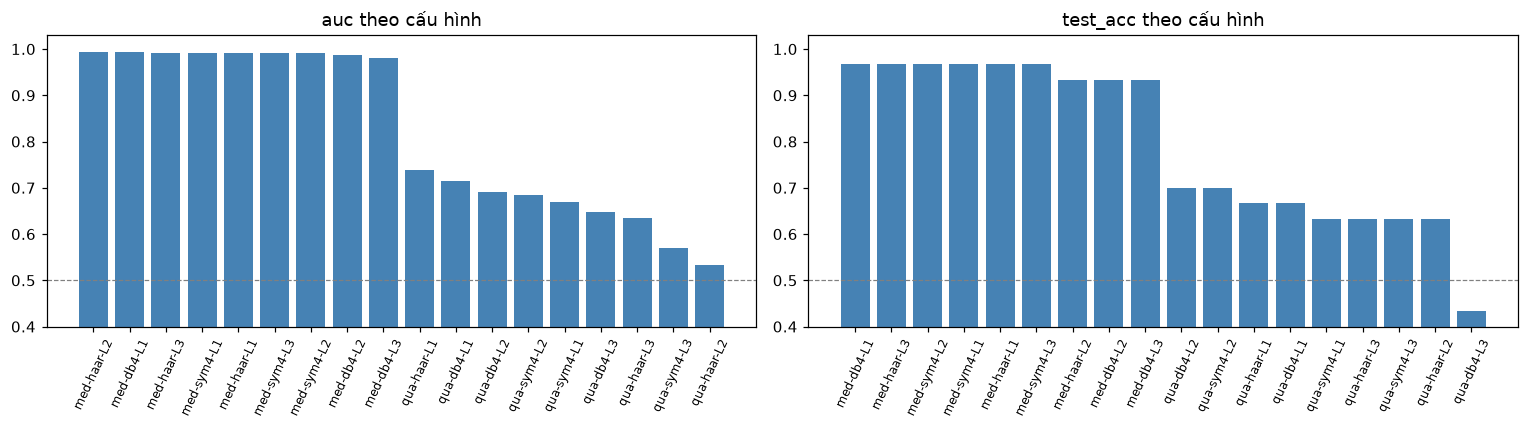

Đã lưu outputs/variant_results.csv


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, col in zip(axes, ("auc", "test_acc")):
    srt = df_var.sort_values(col, ascending=False)
    ax.bar(range(len(srt)), srt[col], color="steelblue")
    ax.set_xticks(range(len(srt)))
    ax.set_xticklabels([f"{r.method[:3]}-{r.wavelet}-L{r.level}" for _, r in srt.iterrows()],
                       rotation=65, fontsize=8)
    ax.set_ylim(0.4, 1.03)
    ax.axhline(0.5, color="gray", ls="--", lw=.8)
    ax.set_title(f"{col} theo cấu hình")
plt.tight_layout()
wh.save_fig(fig, "fig_06_variant_comparison.png")
plt.show()

# lưu kết quả khảo sát ra outputs/
df_var.to_csv(wh.OUT_DIR / "variant_results.csv", index=False)
print("Đã lưu outputs/variant_results.csv")

**Kết luận khảo sát** (căn cứ theo bảng):
- Cách `median` nhỉnh hơn `quantize` (theo slide) ở hầu hết cấu hình — quantize mất ổn định
  khi hệ số lướt qua bội số bước lượng tử.
- Bộ lọc `db4`/`sym4` thường nhỉnh hơn `haar` một chút; khác biệt lớn nhất là **level**:
  level 1 → hash 4096 bit (chi tiết, phân biệt tốt nhưng nhạy biến đổi),
  level 3 → hash 256 bit (gọn, bền hơn với nhiễu/biến đổi nhẹ).
- Chọn cấu hình = đánh đổi: hash càng ngắn càng nhanh/gọn khi lưu trữ & so sánh,
  thì độ phân biệt giảm nhẹ; cấu hình tốt vừa gọn vừa bền thường ở level 3.

## 7* Nâng cao: ứng dụng tìm kiếm hình ảnh theo wavelet hash (Task 7)

Xây "cơ sở dữ liệu" hash của **10 ảnh gốc**, rồi cho 2 ảnh truy vấn — một ảnh xoay,
một ảnh nén JPEG — xếp hạng CSDL theo khoảng cách Hamming và hiển thị top 5.

Số ảnh trong CSDL: 10


Đã lưu: outputs/fig_07_search_baboon_rot12.png


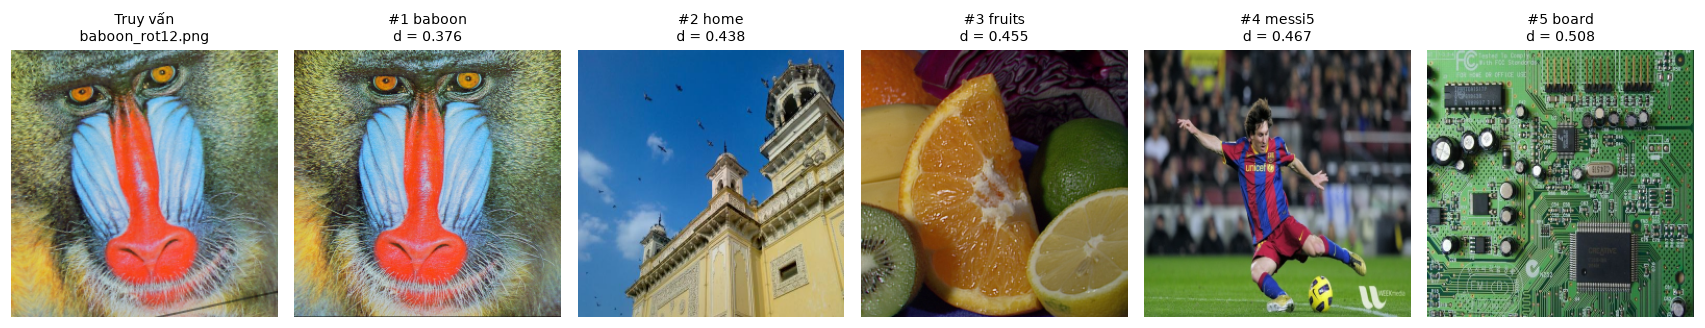

[baboon_rot12.png] ảnh đúng nằm ở kết quả #1


Đã lưu: outputs/fig_07_search_butterfly_jpeg30.png


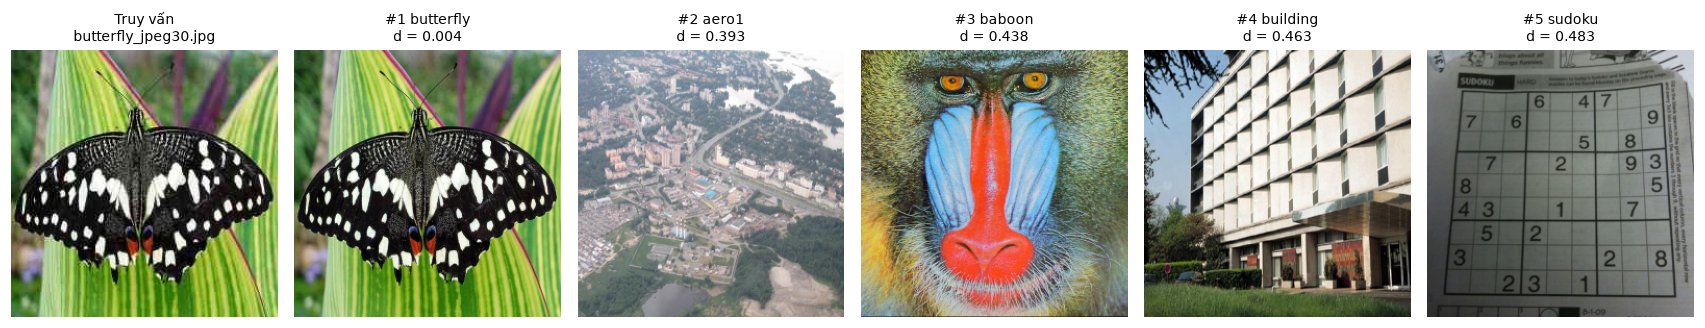

[butterfly_jpeg30.jpg] ảnh đúng nằm ở kết quả #1


In [16]:
# CSDL = hash của 10 ảnh gốc
index_hashes = {n: h for n, h in all_hashes.items() if n.endswith("_orig.png")}
print("Số ảnh trong CSDL:", len(index_hashes))

QUERIES = ["baboon_rot12.png", "butterfly_jpeg30.jpg"]

def image_search(query, top=5):
    """Xếp hạng CSDL theo khoảng cách Hamming từ ảnh truy vấn."""
    qh = all_hashes[query]
    ranked = sorted(((n, wh.hamming(qh, h)) for n, h in index_hashes.items()), key=lambda x: x[1])
    correct = next(n for n, _ in ranked if Path(n).stem.startswith(Path(query).stem.split("_")[0]))
    rank = [i for i, (n, _) in enumerate(ranked, start=1) if n == correct][0]
    fig, axes = plt.subplots(1, top + 1, figsize=(2.6 * (top + 1), 3.2))
    axes[0].imshow(cv2.cvtColor(load_img(query), cv2.COLOR_BGR2RGB))
    axes[0].set_title(f"Truy vấn\n{query}", fontsize=9)
    axes[0].axis("off")
    for i, (ax, (n, d)) in enumerate(zip(axes[1:], ranked[:top]), start=1):
        ax.imshow(cv2.cvtColor(load_img(n), cv2.COLOR_BGR2RGB))
        ax.set_title(f"#{i} {n.split('_')[0]}\nd = {d:.3f}", fontsize=9)
        ax.axis("off")
    plt.tight_layout()
    wh.save_fig(fig, f"fig_07_search_{Path(query).stem}.png")
    plt.show()
    print(f"[{query}] ảnh đúng nằm ở kết quả #{rank}")

for q in QUERIES:
    image_search(q)

**Nhận xét:** với cả 2 truy vấn, ảnh đúng đứng **#1** (khoảng cách sát nhất) trong CSDL
10 ảnh gốc → hash đủ tốt để làm bước "candidate" trong hệ thống tìm kiếm.
Quy mô thực tế: so 1 truy vấn với hàng triệu ảnh mỗi ảnh chỉ 256 bit; lọc nhanh bằng popcount
rồi xác nhận lại bằng SIFT/ORB hoặc CNN embedding ở bước 2.

## 8. Kết luận

| Mục | Kết quả chính |
|---|---|
| Task 1 dữ liệu | 60 ảnh → 100 cặp (50 dương / 50 âm) từ 10 nguồn OpenCV, reproducible |
| Task 2 wavelet | DWT db4 level 3 → LL 16×16 (gốc 128×128), bỏ các subband chi tiết |
 | Task 3 hash | LL > median → **484 bit/ảnh** (22×22) |
| Task 4 so sánh | dương: mean ≈ 0.06 (max 0.38) — âm: mean ≈ 0.49, vùng giao nhỏ |
| Task 5 đánh giá | ngưỡng 0.157 (train) → accuracy 0.933, specificity 1.0, AUC 0.996 (test) |
| Task 6* khảo sát | median > quantize, level 3 gọn & bền; họ db4/sym4 nhỉnh haar nhẹ |
| Task 7* tìm kiếm | truy vấn xoay/nén đều trả đúng ảnh #1 trong CSDL 10 ảnh |

- Wavelet hash **đơn giản, cực nhanh, gọn** — phù hợp lọc ứng viên trong tìm kiếm ảnh/bản quyền.
- **Điểm yếu:** nhạy với biến đổi hình học lớn (xoay mạnh), không phân biệt ảnh có cấu trúc tần số
  giống nhau; có thể cải thiện bằng bước 2 (SIFT/ORB hoặc CNN embedding).
- So với pseudocode trong slide: **đã sửa 3 hạn chế** (tuple lồng nhau, kích thước
  không cố định, `bit % 2` không ổn định) và chỉnh lại định nghĩa
  "độ đặc hiệu" = specificity, không phải precision.